Lesson: Dynamic Quantum Circuits in Qiskit
1. What is a dynamic quantum circuit?
A traditional quantum circuit follows a predefined sequence:
\[
H \rightarrow CX \rightarrow RZ \rightarrow Measure
\]

The gates are defined before execution.

A dynamic quantum circuit can change its subsequent operations based on measurement results.

For example:
\[
H \rightarrow Measure
\]

Then:
- If measurement = 0, execute an X gate.
- If measurement = 1, execute a Z gate.
This process is called classical feedforward.

Four control-flow methods in Qiskit
Your document introduces four methods.
Method	Purpose	Python equivalent
if_test()	Execute operations if a condition is true	if
switch()	Select among multiple conditions	switch/case
for_loop()	Repeat operations a fixed number of times	for
while_loop()	Repeat while a condition remains true	while

Let's understand each.

If statement — Conditional quantum operations
Suppose you want to measure a qubit and apply an X gate only if the result is 1.

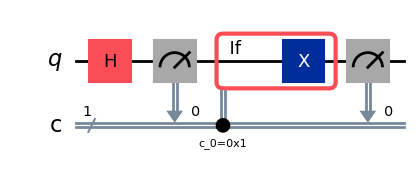

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

q = QuantumRegister(1, "q")
c = ClassicalRegister(1, "c")

qc = QuantumCircuit(q, c)

# Create superposition
qc.h(q[0])

# Mid-circuit measurement
qc.measure(q[0], c[0])

# Conditional operation
with qc.if_test((c[0], 1)):
    qc.x(q[0])

# Final measurement
qc.measure(q[0], c[0])

qc.draw("mpl")

Switch statement — Multiple conditions
Suppose the measurement result determines which operation should execute.

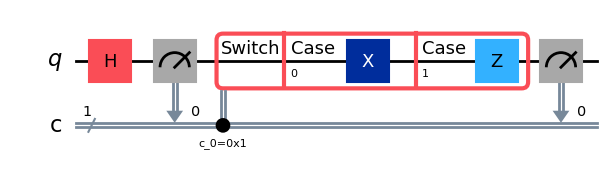

In [2]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1, 1)

qc.h(0)
qc.measure(0, 0)

with qc.switch(qc.clbits[0]) as case:

    with case(0):
        qc.x(0)

    with case(1):
        qc.z(0)

qc.measure(0, 0)

qc.draw("mpl")

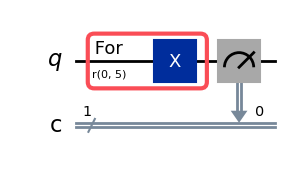

In [3]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1, 1)

with qc.for_loop(range(5)):
    qc.x(0)

qc.measure(0, 0)

qc.draw("mpl")

While loop — Repeating until a condition changes
A while loop allows the circuit to repeat operations based on measurement outcomes.

For example, repeat Hadamard operations and measurements until the result is not 11.

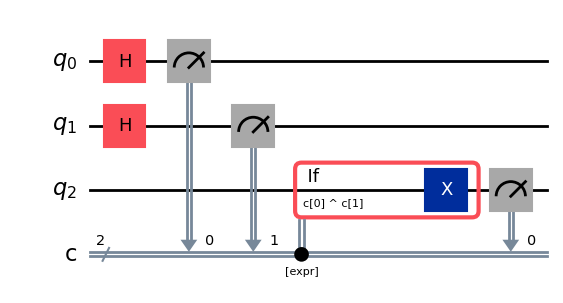

In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit.classical import expr

qc = QuantumCircuit(3, 2)

qc.h([0, 1])

qc.measure([0, 1], [0, 1])

# Calculate parity
parity = expr.bit_xor(
    qc.clbits[0],
    qc.clbits[1]
)

# Apply X if parity equals 1
with qc.if_test(parity):
    qc.x(2)

qc.measure(2, 0)

qc.draw("mpl")

What is store?
Your document also introduces the store instruction.

It stores the result of a classical expression so that you can reuse it.

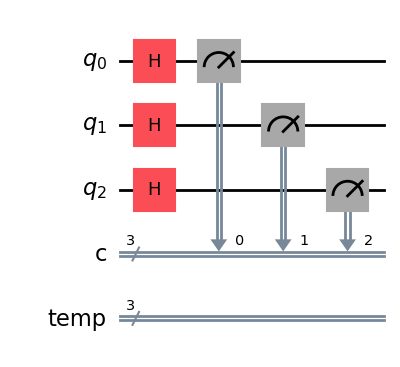

In [7]:
from qiskit import QuantumCircuit, ClassicalRegister
from qiskit.circuit.classical import expr

qc = QuantumCircuit(3, 3)

qc.h([0, 1, 2])
qc.measure([0, 1, 2], [0, 1, 2])

temp = ClassicalRegister(3, "temp")
qc.add_register(temp)

# Store bitwise NOT
qc.store(temp, expr.bit_not(qc.cregs[0]))

qc.draw("mpl")

Why dynamic circuits matter for QFlowPilot
Dynamic circuits introduce another dimension to workload characterization.

Traditional circuit characterization focuses on:
- Number of qubits.
- Gate count.
- Circuit depth.
- Two-qubit gate count.
- Number of shots.
For dynamic circuits, you should additionally consider:
New metric	Meaning
Number of measurements	Mid-circuit measurement operations
Number of conditional branches	How many conditional paths exist
Number of control-flow blocks	If, switch, for, and while blocks
Classical processing	Classical expressions and calculations
Feedforward latency	Time needed to use measurement results for subsequent operations

These properties can influence execution latency, application quality, and hardware compatibility.

Important: Dynamic circuits do not automatically improve quality or reduce execution time. Their benefits depend on the algorithm, hardware support, and classical feedback overhead.
10. Your learning roadmap
I recommend this order:
1. Mid-circuit measurement.
2. Classical feedforward using if_test().
3. Multiple conditions using switch().
4. Repeated execution using for_loop() and while_loop().
5. Classical expressions using XOR, NOT, and AND.
6. Classical storage using store.
7. Dynamic circuit execution on Qiskit Aer.
8. Hardware execution and dynamic-circuit limitations.